# 🏠 Apartment Hunter : estimation du prix d'un bien immobilier

*Projet La Plateforme, B3 IA*

## Contexte

Fixer le prix d'un bien immobilier est difficile : il dépend de nombreuses caractéristiques (surface, nombre de pièces, état, localisation, vue, année de construction…) qui interagissent entre elles. Une estimation trop haute fait traîner la vente, une estimation trop basse fait perdre de l'argent au vendeur.

Nous utilisons le jeu de données **King County House Sales** (`kc_house_data.csv`) : **21 613 ventes** de maisons dans le comté de King (région de Seattle, États-Unis) entre mai 2014 et mai 2015. Chaque ligne décrit une maison vendue et son prix de vente (`price`), qui sera notre **variable cible**.

## Problématique

> **Peut-on estimer le prix d'un bien immobilier à partir de ses caractéristiques ?**

Il s'agit d'un problème de **régression supervisée** : prédire une valeur continue (le prix) à partir de variables explicatives. L'objectif final est de livrer un modèle exploitable via une application web Flask, dans laquelle un utilisateur saisit les caractéristiques d'un bien et obtient une estimation de son prix.

## Plan du notebook

0. **Imports et versions** : bibliothèques utilisées, versions affichées pour la reproductibilité
1. **Chargement et nettoyage** : corrections d'erreurs évidentes, création de variables, choix de la cible
2. **Séparation train / test** : effectuée *avant* tout traitement qui apprend des données, afin d'éviter toute fuite d'information (*data leakage*)
3. **Sélection de features** : Boruta, puis *forward feature selection*
4. **Entraînement et comparaison de modèles** : régression linéaire / Ridge, Random Forest, Gradient Boosting, évalués avec MAE, RMSE et R²
5. **Optimisation par Grid Search** du meilleur modèle
6. **Évaluation finale sur le jeu de test et sauvegarde** du modèle avec `joblib`
7. **Conclusion** : réponse à la problématique, limites et pistes d'amélioration

> Pour la reproductibilité, toutes les opérations aléatoires utilisent `random_state=42`.

## 0. Imports et versions

On importe ici toutes les bibliothèques du notebook, regroupées par usage. Afficher leurs versions permet de reproduire exactement les résultats : un changement de version de scikit-learn, par exemple, peut modifier légèrement un modèle. Ces versions correspondent à celles figées dans `requirements.txt`.

In [1]:
# --- Bibliothèques standard ---
import sys
import time
import warnings
from importlib.metadata import version

# --- Manipulation des données ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Préparation des données et validation ---
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.pipeline import Pipeline

# --- Sélection de features ---
from boruta import BorutaPy
from sklearn.feature_selection import SequentialFeatureSelector

# --- Modèles de régression ---
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

# --- Métriques d'évaluation ---
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Sauvegarde du modèle ---
import joblib

# Graine aléatoire unique, réutilisée partout pour la reproductibilité
RANDOM_STATE = 42

# Options d'affichage : toutes les colonnes visibles, style graphique homogène
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

# Affichage des versions (lues depuis les métadonnées des paquets installés)
print(f"Python       : {sys.version.split()[0]}")
for paquet in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "Boruta", "joblib"]:
    print(f"{paquet:<13}: {version(paquet)}")

Python       : 3.13.1
pandas       : 3.0.6
numpy        : 2.5.4
matplotlib   : 3.11.2
seaborn      : 0.13.2
scikit-learn : 1.9.1
Boruta       : 0.4.3
joblib       : 1.6.0


## 1. Chargement et nettoyage

On part du **dataset brut** `data/raw/kc_house_data.csv`. On n'utilise pas la version Excel retravaillée pour Power BI : elle contient des colonnes dérivées du prix, qui donneraient la réponse au modèle (fuite de la cible), et on veut que chaque transformation soit tracée et justifiée dans ce notebook.

**Ce qui peut se faire avant le split train/test, et ce qui ne le peut pas :**

| Avant le split (sur tout le dataset) | Après le split (ajusté sur le train uniquement) |
|---|---|
| Corriger une faute de saisie évidente | Imputation (moyenne, médiane…) |
| Supprimer une ligne physiquement impossible | Mise à l'échelle (`StandardScaler`…) |
| Créer une variable par une règle fixe (ex. `house_age = sale_year - yr_built`) | Encodage qui dépend des données (one-hot sur les catégories vues, *target encoding*) |
| Appliquer une fonction fixe (ex. `log1p`) | Sélection de features (Boruta, forward selection) |

La règle : un traitement de la colonne de gauche **n'apprend rien des données**. Il donne le même résultat pour une ligne, quelles que soient les autres lignes. Un traitement de la colonne de droite **calcule des statistiques** sur les données. Fait avant le split, il laisserait passer de l'information du jeu de test vers l'entraînement, et l'évaluation finale serait trop optimiste.

### 1.1 Chargement et premier aperçu

**Quoi :** on charge le CSV, puis on affiche ses dimensions, les types des colonnes, les premières lignes, les valeurs manquantes et les lignes en double.

**Pourquoi :** avant toute transformation, il faut vérifier que le fichier est bien lu (bons types, bon nombre de lignes) et repérer les problèmes de qualité qui guideront le nettoyage.

In [2]:
CHEMIN_BRUT = "../data/raw/kc_house_data.csv"
df = pd.read_csv(CHEMIN_BRUT)

print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes\n")
print("Types des colonnes :")
print(df.dtypes)

display(df.head())

print(f"Valeurs manquantes (total) : {df.isna().sum().sum()}")
print(f"Lignes entièrement dupliquées : {df.duplicated().sum()}")

Dimensions : 21613 lignes x 21 colonnes

Types des colonnes :
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Valeurs manquantes (total) : 0
Lignes entièrement dupliquées : 0


**Constat :** 21 613 lignes et 21 colonnes, aucune valeur manquante, aucune ligne entièrement dupliquée. Les types sont cohérents. Deux colonnes demandent une attention particulière :
- `date` est lue comme du texte (format `20141013T000000`) : on la convertira en date.
- `zipcode` est lu comme un entier, mais c'est un code postal, donc une catégorie et non une quantité (voir 1.9).

### 1.2 Doublons d'identifiant (`id`)

**Quoi :** on compte les `id` qui apparaissent plusieurs fois et on regarde un exemple.

**Pourquoi :** un même `id` sur plusieurs lignes peut signaler un vrai doublon (même ligne saisie deux fois, à supprimer) ou une même maison **vendue plusieurs fois** (deux ventes réelles, à garder). Il faut savoir lequel avant de décider.

In [3]:
occurrences = df["id"].value_counts()
ids_multiples = occurrences[occurrences > 1]

print(f"Nombre d'id apparaissant plusieurs fois : {len(ids_multiples)}")
print(f"Nombre de lignes concernées              : {ids_multiples.sum()}")
print(f"Nombre maximal de ventes pour un même id : {ids_multiples.max()}")
print(f"Doublons sur le couple (id, date)        : {df.duplicated(subset=['id', 'date']).sum()}")

# Exemple : une maison vendue plusieurs fois
exemple_id = ids_multiples.index[0]
display(df.loc[df["id"] == exemple_id, ["id", "date", "price", "bedrooms", "sqft_living", "yr_renovated"]])

Nombre d'id apparaissant plusieurs fois : 176
Nombre de lignes concernées              : 353
Nombre maximal de ventes pour un même id : 3
Doublons sur le couple (id, date)        : 0


,id,date,price,bedrooms,sqft_living,yr_renovated
17602,795000620,20140924T000000,115000.0,3,1080,0
17603,795000620,20141215T000000,124000.0,3,1080,0
17604,795000620,20150311T000000,157000.0,3,1080,0


**Décision : on garde ces lignes.** Aucun couple (`id`, `date`) n'est dupliqué : chaque ligne correspond à une **vente distincte** de la même maison à une date différente (revente). Le prix change souvent d'une vente à l'autre, ce qui reflète l'évolution du marché ou de la maison. Ce sont des observations légitimes, pas des erreurs de saisie.

> Limite à garder en tête : une même maison peut se retrouver à la fois dans le train et dans le test, ce qui rend la tâche un peu plus facile pour le modèle. L'effet est négligeable ici (353 lignes sur 21 613, soit 1,6 %).

### 1.3 Correction de la maison à 33 chambres

**Quoi :** une maison déclare 33 chambres. On la corrige en **3 chambres**.

**Pourquoi :** c'est une faute de saisie évidente (un « 3 » tapé deux fois). Sa surface habitable (1 620 sqft, soit environ 150 m²) avec 1,75 salle de bain correspond à une maison typique de 3 chambres. La surface médiane des maisons de 3 chambres est d'environ 1 680 sqft, alors que même les maisons de 10 chambres et plus font plus de 3 000 sqft. Corriger plutôt que supprimer garde une vente réelle et cohérente. Cette correction concerne une seule ligne et n'utilise aucune statistique apprise sur les données : elle peut se faire avant le split.

In [4]:
masque_33 = df["bedrooms"] == 33
assert masque_33.sum() == 1, "On attend exactement une maison à 33 chambres"
index_33 = df.index[masque_33][0]
colonnes_affichees = ["id", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors"]

print("Surface habitable médiane selon le nombre de chambres (pour comparaison) :")
print(df.groupby("bedrooms")["sqft_living"].median().loc[[2, 3, 4, 5, 10, 11]].to_string())

print("\nAVANT correction :")
display(df.loc[[index_33], colonnes_affichees])

df.loc[index_33, "bedrooms"] = 3

print("APRÈS correction :")
display(df.loc[[index_33], colonnes_affichees])

Surface habitable médiane selon le nombre de chambres (pour comparaison) :
bedrooms
2     1140.0
3     1680.0
4     2410.0
5     2870.0
10    3610.0
11    3000.0

AVANT correction :


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors
15870,2402100895,640000.0,33,1.75,1620,6000,1.0


APRÈS correction :


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors
15870,2402100895,640000.0,3,1.75,1620,6000,1.0


### 1.4 Suppression des maisons sans chambre ou sans salle de bain

**Quoi :** on supprime les lignes où `bedrooms == 0` ou `bathrooms == 0`.

**Pourquoi :** une maison vendue comme habitation avec 0 chambre ou 0 salle de bain est incohérente. Il s'agit probablement d'une erreur de saisie ou d'un bien atypique (terrain, local non résidentiel). Contrairement au cas précédent, on ne peut pas deviner la bonne valeur, donc on supprime ces lignes. Elles sont très peu nombreuses, donc on perd très peu d'information. Supprimer une ligne selon une règle fixe n'apprend rien des données : cela peut se faire avant le split.

In [5]:
masque_incoherent = (df["bedrooms"] == 0) | (df["bathrooms"] == 0)
print(f"Maisons avec 0 chambre      : {(df['bedrooms'] == 0).sum()}")
print(f"Maisons avec 0 salle de bain : {(df['bathrooms'] == 0).sum()}")

display(df.loc[masque_incoherent, ["id", "price", "bedrooms", "bathrooms", "sqft_living"]])

nb_avant = len(df)
df = df.loc[~masque_incoherent].reset_index(drop=True)
print(f"Lignes supprimées : {nb_avant - len(df)}  ({nb_avant} -> {len(df)} lignes)")

Maisons avec 0 chambre      : 13
Maisons avec 0 salle de bain : 10


,id,price,bedrooms,bathrooms,sqft_living
875,6306400140,1095000.0,0,0.00,3064
1149,3421079032,75000.0,1,0.00,670
3119,3918400017,380000.0,0,0.00,1470
3467,1453602309,288000.0,0,1.50,1430
4868,6896300380,228000.0,0,1.00,390
5832,5702500050,280000.0,1,0.00,600
6994,2954400190,1295650.0,0,0.00,4810
8477,2569500210,339950.0,0,2.50,2290
8484,2310060040,240000.0,0,2.50,1810
9773,3374500520,355000.0,0,0.00,2460


Lignes supprimées : 16  (21613 -> 21597 lignes)


### 1.5 Création de variables (*feature engineering*)

**Quoi et pourquoi, variable par variable :**

- **`sale_year` et `sale_month`** (extraites de `date`, qui est ensuite supprimée) : les modèles ne savent pas exploiter une chaîne de caractères comme `20141013T000000`. L'année capte l'évolution générale du marché entre 2014 et 2015. Le mois capte une éventuelle **saisonnalité**, car le marché immobilier est plus actif au printemps et en été.
- **`house_age = sale_year - yr_built`** : l'âge de la maison **au moment de la vente** est plus parlant que son année de construction. `yr_built` devient alors redondante : on la supprimera en 1.7.
- **`renovated`** (1 si `yr_renovated > 0`, sinon 0), puis suppression de `yr_renovated` : dans cette colonne, `0` ne veut pas dire « l'an 0 » mais « jamais rénovée ». Laissée telle quelle, elle placerait les maisons non rénovées 2 000 ans avant les autres, ce qui fausserait tout modèle linéaire. Un indicateur binaire représente correctement l'information.
- **`has_basement`** (1 si `sqft_basement > 0`, sinon 0) : avoir un sous-sol ou non est une information distincte de sa surface, et elle est plus simple à exploiter pour certains modèles.

Toutes ces variables sont calculées ligne par ligne avec une règle fixe, sans statistique apprise : aucun risque de fuite.

In [6]:
# Date de vente : conversion puis extraction de l'année et du mois
df["date"] = pd.to_datetime(df["date"], format="%Y%m%dT%H%M%S")
df["sale_year"] = df["date"].dt.year
df["sale_month"] = df["date"].dt.month
df = df.drop(columns="date")

# Âge de la maison au moment de la vente
df["house_age"] = df["sale_year"] - df["yr_built"]

# Indicateur de rénovation (0 dans yr_renovated = jamais rénovée)
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
df = df.drop(columns="yr_renovated")

# Indicateur de présence d'un sous-sol
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)

print(f"Années de vente : {sorted(df['sale_year'].unique().tolist())}")
print(f"Maisons rénovées : {df['renovated'].sum()} ({df['renovated'].mean():.1%})")
print(f"Maisons avec sous-sol : {df['has_basement'].sum()} ({df['has_basement'].mean():.1%})")
print(f"Âge : min = {df['house_age'].min()}, max = {df['house_age'].max()}")
print(f"Maisons avec un âge négatif : {(df['house_age'] < 0).sum()}")

display(df[["sale_year", "sale_month", "yr_built", "house_age", "renovated", "sqft_basement", "has_basement"]].head())

Années de vente : [2014, 2015]
Maisons rénovées : 914 (4.2%)
Maisons avec sous-sol : 8487 (39.3%)
Âge : min = -1, max = 115
Maisons avec un âge négatif : 12


,sale_year,sale_month,yr_built,house_age,renovated,sqft_basement,has_basement
0,2014,10,1955,59,0,0,0
1,2014,12,1951,63,1,400,1
2,2015,2,1933,82,0,0,0
3,2014,12,1965,49,0,910,1
4,2015,2,1987,28,0,0,0


**Remarque sur les âges négatifs :** quelques maisons ont `house_age = -1`. Elles ont été vendues **avant la fin de leur construction** (vente sur plan en 2014 d'une maison achevée en 2015). Ce n'est pas une erreur : la valeur -1 est cohérente (une maison neuve, même pas encore livrée), donc on la garde.

### 1.6 Suppression de `sqft_above` et `id`

**Quoi :** on vérifie que `sqft_living = sqft_above + sqft_basement` sur toutes les lignes, puis on supprime `sqft_above` et `id`.

**Pourquoi :**
- **`sqft_above`** : si l'égalité est toujours vraie, `sqft_above` se déduit exactement des deux autres colonnes (**colinéarité parfaite**). Elle n'apporte aucune information nouvelle. Pour une régression linéaire, elle rend même les coefficients instables et ininterprétables. On garde `sqft_living` (la surface totale, la plus parlante) et `sqft_basement`.
- **`id`** : c'est un identifiant administratif attribué arbitrairement. Il n'a aucun lien causal avec le prix. Le garder risquerait que le modèle apprenne des corrélations dues au hasard.

In [7]:
colinearite = (df["sqft_living"] == df["sqft_above"] + df["sqft_basement"])
print(f"sqft_living == sqft_above + sqft_basement sur {colinearite.sum()} / {len(df)} lignes")
assert colinearite.all(), "La relation de colinéarité n'est pas vérifiée partout"

df = df.drop(columns=["sqft_above", "id"])
print(f"Colonnes restantes ({df.shape[1]}) : {list(df.columns)}")

sqft_living == sqft_above + sqft_basement sur 21597 / 21597 lignes
Colonnes restantes (22) : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'renovated', 'has_basement']


### 1.7 Suppression de `yr_built` (redondante avec `house_age`)

**Quoi :** on montre que `yr_built` et `house_age` portent la même information, puis on supprime `yr_built`.

**Pourquoi :** par construction, `house_age = sale_year - yr_built`, et `sale_year` ne prend que deux valeurs (2014 et 2015). Connaître l'une des deux colonnes donne donc l'autre à un an près :
- pour la **régression linéaire et Ridge**, garder les deux crée une colinéarité (exacte avec `sale_year`), ce qui rend les coefficients instables et ininterprétables ;
- pour les **modèles à arbres** et la sélection de features, deux colonnes jumelles se partagent l'importance, et chacune paraît moins utile qu'elle ne l'est.

On garde **`house_age`** : elle est plus directe à interpréter (« une maison de 30 ans ») et décrit l'état de la maison au moment de la vente. Dans l'application, l'utilisateur pourra saisir l'année de construction, et l'âge sera calculé automatiquement.

house_age + yr_built == sale_year sur toutes les lignes
Corrélation entre yr_built et house_age : -0.9999


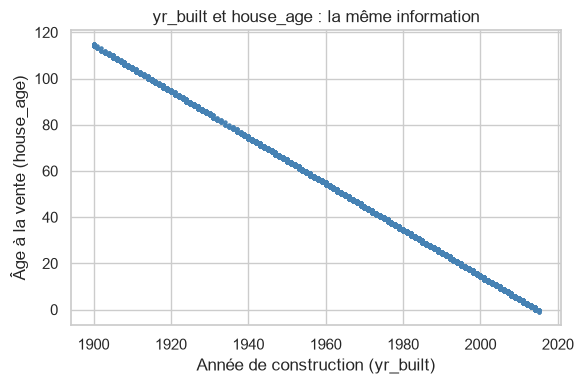

Colonnes restantes (21) : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'renovated', 'has_basement']


In [8]:
# Relation exacte : house_age + yr_built = sale_year sur toutes les lignes
assert (df["house_age"] + df["yr_built"] == df["sale_year"]).all(), "La relation house_age = sale_year - yr_built n'est pas vérifiée"
print("house_age + yr_built == sale_year sur toutes les lignes")
print(f"Corrélation entre yr_built et house_age : {df['yr_built'].corr(df['house_age']):.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["yr_built"], df["house_age"], s=4, alpha=0.3, color="steelblue")
ax.set_xlabel("Année de construction (yr_built)")
ax.set_ylabel("Âge à la vente (house_age)")
ax.set_title("yr_built et house_age : la même information")
plt.tight_layout()
plt.show()

df = df.drop(columns="yr_built")
print(f"Colonnes restantes ({df.shape[1]}) : {list(df.columns)}")

### 1.8 Distribution de la cible : `price` ou `log1p(price)` ?

**Quoi :** on compare la distribution du prix brut et celle de `log1p(price)` = log(1 + prix), avec leur coefficient d'asymétrie (*skewness*). Une distribution symétrique a une skewness proche de 0.

**Pourquoi :** les prix immobiliers ont en général une distribution très **asymétrique à droite** : beaucoup de maisons à prix moyen, quelques maisons de luxe très chères. On vérifie si c'est le cas ici, car cela conditionne le choix de la cible.

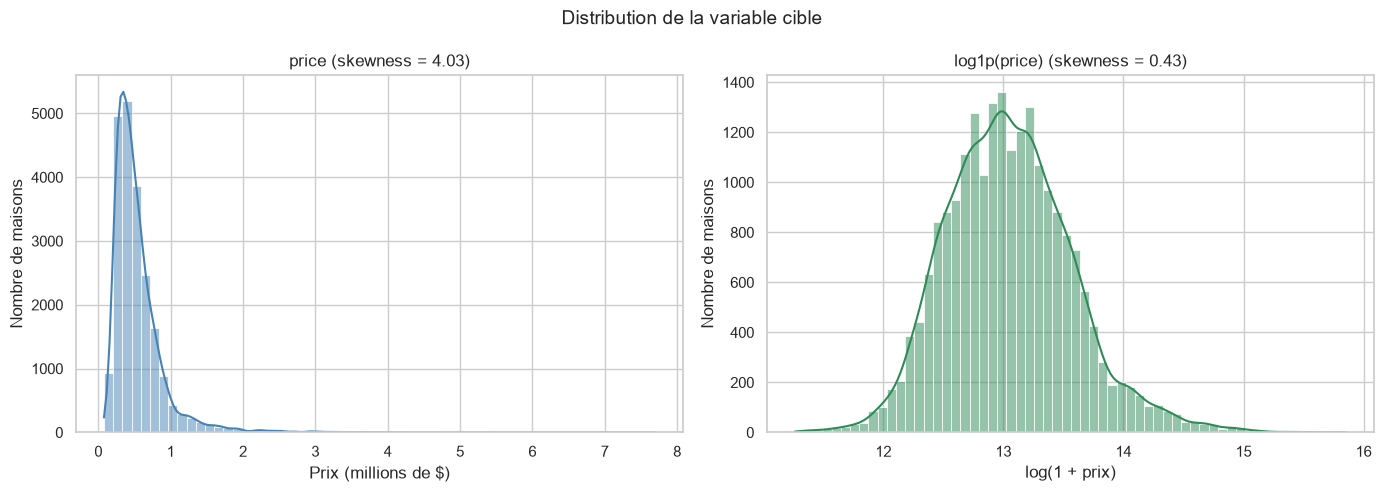

Skewness de price        : 4.03
Skewness de log1p(price) : 0.43


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["price"] / 1e6, bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"price (skewness = {df['price'].skew():.2f})")
axes[0].set_xlabel("Prix (millions de $)")
axes[0].set_ylabel("Nombre de maisons")

sns.histplot(np.log1p(df["price"]), bins=60, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p(price) (skewness = {np.log1p(df['price']).skew():.2f})")
axes[1].set_xlabel("log(1 + prix)")
axes[1].set_ylabel("Nombre de maisons")

plt.suptitle("Distribution de la variable cible", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Skewness de price        : {df['price'].skew():.2f}")
print(f"Skewness de log1p(price) : {np.log1p(df['price']).skew():.2f}")

**Décision : la cible des modèles sera `log1p(price)`.**

- **Distribution :** le prix brut est fortement asymétrique (skewness ≈ 4,0, avec une longue traîne jusqu'à près de 8 M$). Après `log1p`, la distribution est presque en cloche : la skewness tombe à ≈ 0,4, une asymétrie faible (on parle en général de forte asymétrie au-delà de 1). Les régressions linéaires et Ridge supposent des erreurs à peu près symétriques et de variance constante, et le log s'en rapproche nettement.
- **Poids des maisons de luxe :** avec le prix brut, une erreur de 100 000 $ sur une maison à 5 M$ pèse autant que sur une maison à 300 000 $, et les quelques maisons très chères dominent l'apprentissage. En log, le modèle minimise des **erreurs relatives** (en %), ce qui correspond mieux au besoin : se tromper de 10 % est aussi grave pour une petite maison que pour une grande.
- **Pas de fuite :** `log1p` est une fonction fixe qui n'apprend rien des données, donc on peut l'appliquer sans risque. Pour revenir au prix en dollars, on appliquera `np.expm1()` aux prédictions. Les métriques finales (MAE, RMSE) seront calculées **en dollars**, pour rester interprétables.

On garde `price` en dollars dans le fichier nettoyé. La transformation sera appliquée au moment de la modélisation.

### 1.9 `zipcode` : une variable catégorielle

**Quoi :** on regarde `zipcode` sans le transformer.

**Pourquoi :** `zipcode` est stocké comme un nombre, mais c'est un **code postal**, c'est-à-dire une étiquette de zone géographique. Les calculs sur ces nombres n'ont aucun sens : 98 178 n'est pas « plus grand » ou « deux fois » 98 039, et deux codes proches ne désignent pas forcément des quartiers semblables. Un modèle linéaire qui le lirait comme un nombre en tirerait une relation absurde.

Il faudra donc l'**encoder** (par exemple en one-hot, ou en *target encoding* avec le prix moyen par zone). Cet encodage dépend des données : la liste des catégories, et surtout le prix moyen par zone pour le target encoding, qui utilise la cible. **Il se fera donc après le split, ajusté sur le train uniquement.** Ici, on se contente de constater sa nature.

In [10]:
print(f"Nombre de codes postaux distincts : {df['zipcode'].nunique()}")

prix_median_zip = df.groupby("zipcode")["price"].median().sort_values()
print(f"\nPrix médian par zipcode : de {prix_median_zip.iloc[0]:,.0f} $ ({prix_median_zip.index[0]}) "
      f"à {prix_median_zip.iloc[-1]:,.0f} $ ({prix_median_zip.index[-1]})")
print("Exemple de trois codes consécutifs aux prix très différents :")
print(prix_median_zip.loc[[98038, 98039, 98040]].apply(lambda p: f"{p:,.0f} $").to_string())

Nombre de codes postaux distincts : 70

Prix médian par zipcode : de 235,000 $ (98002) à 1,892,500 $ (98039)
Exemple de trois codes consécutifs aux prix très différents :
zipcode
98038      342,000 $
98039    1,892,500 $
98040      993,750 $


### 1.10 Vérification finale et sauvegarde

**Quoi :** on affiche les dimensions finales, on vérifie qu'il ne reste aucune valeur manquante, puis on sauvegarde le dataset dans `data/processed/kc_house_clean.csv`.

**Pourquoi :** sauvegarder le dataset nettoyé fige une version de référence. On peut la recharger sans refaire le nettoyage, et l'application ou d'autres notebooks peuvent s'en servir. Ce fichier ne contient **que** des transformations sans apprentissage : il reste sûr à utiliser avant le split.

In [11]:
print(f"Dimensions finales : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"Valeurs manquantes : {df.isna().sum().sum()}")
assert df.isna().sum().sum() == 0, "Il reste des valeurs manquantes"

CHEMIN_PROPRE = "../data/processed/kc_house_clean.csv"
df.to_csv(CHEMIN_PROPRE, index=False)
print(f"Dataset nettoyé sauvegardé dans {CHEMIN_PROPRE}")

display(df.head())

Dimensions finales : 21597 lignes x 21 colonnes
Valeurs manquantes : 0
Dataset nettoyé sauvegardé dans ../data/processed/kc_house_clean.csv


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,renovated,has_basement
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,0,98178,47.5112,-122.257,1340,5650,2014,10,59,0,0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,400,98125,47.7210,-122.319,1690,7639,2014,12,63,1,1
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,0,98028,47.7379,-122.233,2720,8062,2015,2,82,0,0
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,910,98136,47.5208,-122.393,1360,5000,2014,12,49,0,1
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,0,98074,47.6168,-122.045,1800,7503,2015,2,28,0,0


## 2. Séparation train / test

**Quoi :** on définit les variables explicatives `X` (toutes les colonnes sauf `price`) et la cible `y = log1p(price)` (voir 1.8), puis on les sépare en un jeu d'entraînement (80 %) et un jeu de test (20 %), avec `random_state=RANDOM_STATE`.

**Pourquoi :**
- Le jeu de test joue le rôle de **maisons jamais vues**. Il ne servira **qu'une seule fois**, à l'évaluation finale (section 6). Aucune décision ne doit s'appuyer dessus : ni l'encodage, ni la sélection de features, ni le choix du modèle, ni les hyperparamètres. Sinon, la performance annoncée serait trop optimiste. Toutes les comparaisons intermédiaires se feront par **validation croisée sur le train**.
- **80 / 20** est un compromis classique : environ 17 000 ventes pour apprendre, et environ 4 300 pour une mesure finale stable.
- Le découpage est aléatoire (sans stratification, la cible étant continue). On vérifie ensuite que la distribution des prix est comparable dans les deux jeux.

In [12]:
# Variables explicatives : toutes les colonnes sauf la cible
X = df.drop(columns="price")
# Cible : log(1 + prix), plus symétrique que le prix brut
y = np.log1p(df["price"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train : {X_train.shape[0]} lignes x {X_train.shape[1]} features ({len(X_train) / len(X):.0%})")
print(f"Test  : {X_test.shape[0]} lignes x {X_test.shape[1]} features ({len(X_test) / len(X):.0%})")

# Vérification : les deux jeux ont des distributions de prix comparables (en dollars)
comparaison = pd.DataFrame({
    "train ($)": np.expm1(y_train).describe(),
    "test ($)": np.expm1(y_test).describe(),
}).loc[["mean", "25%", "50%", "75%", "max"]]
comparaison.index = ["moyenne", "1er quartile", "médiane", "3e quartile", "maximum"]
display(comparaison.round(0))

Train : 17277 lignes x 20 features (80%)
Test  : 4320 lignes x 20 features (20%)


,train ($),test ($)
moyenne,541420.0,535336.0
1er quartile,324000.0,319800.0
médiane,450000.0,450000.0
3e quartile,645500.0,637500.0
maximum,7700000.0,7062500.0


**Constat :** les deux jeux ont des prix moyens, médians et des quartiles très proches. Le découpage aléatoire n'a pas créé de déséquilibre. À partir d'ici, `X_test` et `y_test` sont **mis de côté** jusqu'à la section 6.

> **Rappel de la limite des reventes (voir 1.2) :** 176 maisons ont été vendues plusieurs fois (353 lignes, soit 1,6 % du dataset). Le découpage étant aléatoire, une vente peut se retrouver dans le train et une autre vente de la même maison dans le test. Le modèle a alors déjà « vu » cette maison, ce qui rend la prédiction un peu plus facile. Vu la faible proportion, l'effet sur les métriques est négligeable. Une alternative plus stricte serait un découpage groupé par `id` (`GroupShuffleSplit`).

## 3. Sélection de features

**Objectif :** identifier les variables réellement utiles pour prédire le prix, avec deux méthodes complémentaires :
- **Boruta** (3.3) répond à la question « cette variable apporte-t-elle de l'information ? » (approche *all-relevant*) ;
- la **forward selection** (3.4) répond à « quel est le plus petit groupe de variables qui suffit ? » (approche *minimal-optimal*), en écartant les variables redondantes.

**Règle :** toute cette section travaille **uniquement sur le train**. L'encodage de `zipcode` et les deux méthodes de sélection apprennent des données : les faire sur tout le dataset ferait fuiter de l'information du jeu de test.

La liste finale de features sera arrêtée **après** ces analyses, en croisant la performance et l'utilisabilité dans l'application (un utilisateur doit pouvoir saisir chaque variable).

### 3.1 Encodage de `zipcode` par *target encoding*

**Quoi :** on remplace chaque code postal par le **log-prix moyen de sa zone**, calculé sur le train avec `TargetEncoder(cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))`.

**Pourquoi le target encoding plutôt que le one-hot :**
- **Le one-hot crée 70 colonnes** binaires (une par code postal), dont beaucoup ne concernent que quelques dizaines de ventes. Boruta et la forward selection devraient évaluer chaque code postal séparément, ce qui est lent (la forward selection teste chaque colonne restante à chaque étape) et peu parlant : on veut savoir si **la localisation** compte, pas si le code 98 039 compte.
- **Le target encoding garde une seule colonne numérique**, ordonnée par niveau de prix de la zone. C'est exactement l'information utile (« quartier cher ou bon marché »). Les modèles à arbres l'exploitent en une seule coupure, et les modèles linéaires peuvent l'utiliser directement.
- Dans le formulaire Flask, l'utilisateur saisira simplement un code postal, que l'encodeur convertira.

**Le risque, et comment `TargetEncoder` le gère :** l'encodage utilise la cible, donc une ligne pourrait « voir » son propre prix dans sa feature (fuite). `fit_transform` applique un **cross-fitting** : le train est découpé en 5 blocs (mélangés, avec `random_state=RANDOM_STATE` pour la reproductibilité), et l'encodage de chaque ligne est calculé uniquement à partir des 4 autres blocs. De plus, les zones peu représentées sont **lissées** vers la moyenne globale (`smooth="auto"`), ce qui évite de leur attribuer une moyenne bruitée.

> On passe le découpage via `cv=KFold(...)` plutôt que `random_state=` directement : depuis scikit-learn 1.9, les paramètres `shuffle` et `random_state` de `TargetEncoder` sont dépréciés (suppression prévue en 1.11).

> `fit_transform` (avec cross-fitting) n'est pas équivalent à `fit` puis `transform`. Pour le test et l'application, on utilisera `transform`, qui applique l'encodage appris sur tout le train. Pour l'entraînement des modèles (section 4), l'encodeur sera placé dans un `Pipeline`, afin d'être réajusté à chaque pli de validation croisée.

In [13]:
encodeur_zip = TargetEncoder(
    target_type="continuous",
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
)

# Copie du train, avec zipcode remplacé par son encodage (cross-fitting via fit_transform)
X_train_enc = X_train.copy()
X_train_enc["zipcode"] = encodeur_zip.fit_transform(X_train[["zipcode"]], y_train).ravel()

# Encodage appris par zone sur tout le train, reconverti en dollars pour être lisible
encodage_par_zip = pd.Series(encodeur_zip.encodings_[0], index=encodeur_zip.categories_[0])
print(f"Codes postaux appris sur le train : {len(encodage_par_zip)}")
print(f"Moyenne globale du train : {np.expm1(encodeur_zip.target_mean_):,.0f} $ (prix typique)")

extremes = encodage_par_zip.sort_values().iloc[[0, 1, 2, -3, -2, -1]]
print("\nZones les moins chères et les plus chères (prix typique encodé) :")
print(np.expm1(extremes).apply(lambda p: f"{p:,.0f} $").to_string())

display(X_train_enc[["zipcode"]].rename(columns={"zipcode": "zipcode encodé"})
        .assign(zipcode_original=X_train["zipcode"]).head())

Codes postaux appris sur le train : 70
Moyenne globale du train : 464,948 $ (prix typique)

Zones les moins chères et les plus chères (prix typique encodé) :
98002      230,243 $
98168      230,768 $
98032      243,039 $
98040    1,103,329 $
98004    1,172,823 $
98039    1,983,907 $


,zipcode encodé,zipcode_original
6243,13.158789,98144
8986,12.905111,98045
9419,13.362611,98074
10155,13.098951,98034
10436,13.212643,98103


### 3.2 Corrélations entre features et avec la cible

**Quoi :** on calcule la matrice de corrélation de Pearson sur le train (avec `zipcode` encodé et la cible `log_price`), puis on liste les features les plus corrélées à la cible et les paires de features très corrélées entre elles (|r| > 0,8).

**Pourquoi :** c'est une première lecture rapide. Une forte corrélation avec la cible signale une variable prometteuse. Une forte corrélation entre deux features signale une **redondance** : elle gêne les modèles linéaires (coefficients instables), et l'une des deux pourra probablement être retirée sans perte. Limite : Pearson ne mesure que les relations **linéaires**. Une variable comme `lat` ou `long`, dont l'effet sur le prix n'est pas monotone, peut être sous-estimée. C'est pourquoi on complète cette lecture par Boruta et la forward selection.

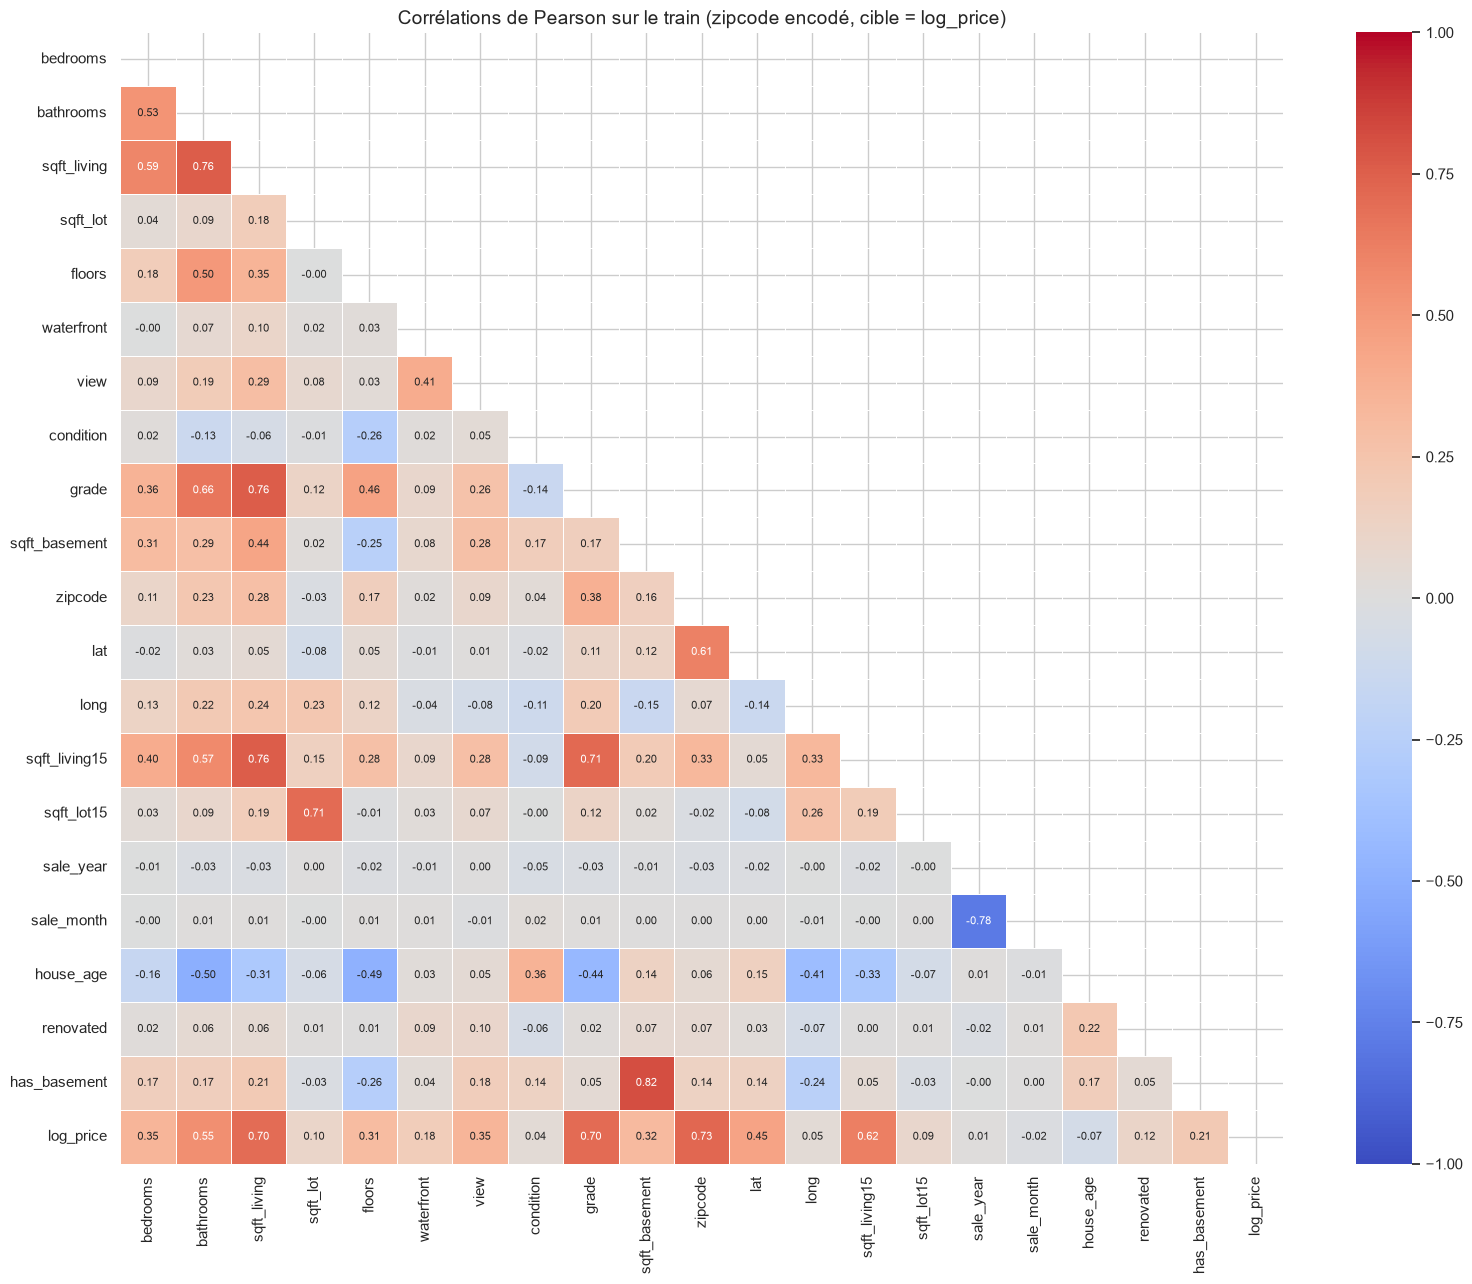

Corrélation avec log(price) :
zipcode          0.725
grade            0.704
sqft_living      0.695
sqft_living15    0.623
bathrooms        0.553
lat              0.449
view             0.351
bedrooms         0.348
sqft_basement    0.319
floors           0.312
has_basement     0.214
waterfront       0.181
renovated        0.116
sqft_lot         0.103
sqft_lot15       0.091
house_age       -0.072
long             0.046
condition        0.042
sale_month      -0.018
sale_year        0.009

Paires de features avec |r| > 0,8 : 1
sqft_basement  has_basement    0.82


In [14]:
donnees_corr = X_train_enc.assign(log_price=y_train)
matrice_corr = donnees_corr.corr()

# Heatmap du triangle inférieur (la matrice est symétrique)
masque_triangle = np.triu(np.ones_like(matrice_corr, dtype=bool))
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(matrice_corr, mask=masque_triangle, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, linewidths=0.5, ax=ax)
ax.set_title("Corrélations de Pearson sur le train (zipcode encodé, cible = log_price)", fontsize=14)
plt.tight_layout()
plt.show()

# Corrélation de chaque feature avec la cible, triée par valeur absolue
corr_cible = matrice_corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False)
print("Corrélation avec log(price) :")
print(corr_cible.round(3).to_string())

# Paires de features fortement corrélées entre elles (triangle supérieur strict, sans doublon)
corr_features = matrice_corr.drop(index="log_price", columns="log_price")
triangle_sup = np.triu(np.ones(corr_features.shape, dtype=bool), k=1)
paires = corr_features.where(triangle_sup).stack()
paires_fortes = paires[paires.abs() > 0.8].sort_values(key=abs, ascending=False)
print(f"\nPaires de features avec |r| > 0,8 : {len(paires_fortes)}")
print(paires_fortes.round(3).to_string())

**Lecture des corrélations :**
- **Les plus liées à `log(price)` :** `zipcode` encodé (0,73), `grade` (0,70), `sqft_living` (0,70), `sqft_living15` (0,62) et `bathrooms` (0,55). Le prix dépend donc avant tout de la **localisation**, de la **qualité de construction** et de la **surface**. `lat` (0,45) confirme l'effet géographique : le nord du comté (Seattle, Bellevue) est plus cher que le sud.
- **Quasi nulles linéairement :** `sale_year`, `sale_month`, `condition`, `long` et `house_age` (|r| < 0,08). Cela ne veut pas dire qu'elles sont inutiles : leur effet peut être non linéaire. Par exemple, les maisons très anciennes et les maisons neuves sont toutes deux recherchées, et `long` agit à travers des zones précises. Boruta et la forward selection trancheront.
- **Paire au-dessus de 0,8 :** une seule, `sqft_basement` / `has_basement` (0,82), ce qui est logique puisque `has_basement` est dérivée de `sqft_basement`. L'une des deux est redondante.
- **Juste en dessous du seuil :** `sale_year` / `sale_month` (-0,78, car les ventes de 2015 s'arrêtent en mai), `sqft_living` / `grade` (0,76), `sqft_living` / `sqft_living15` (0,76) et `sqft_living` / `bathrooms` (0,76). Ce sont des redondances partielles, dont la forward selection devrait écarter une partie.

### 3.3 Boruta

**Quoi :** Boruta crée pour chaque feature une copie dont les valeurs sont mélangées aléatoirement (*shadow feature*), donc sans aucun lien avec le prix. Il entraîne une forêt aléatoire sur l'ensemble, puis compare l'importance de chaque vraie feature à celle de la **meilleure shadow feature**. L'opération est répétée, et un test statistique classe chaque feature :
- **confirmée** : elle bat le hasard significativement plus souvent qu'attendu ;
- **rejetée** : elle ne fait pas mieux que du bruit ;
- **tentative** : pas assez d'itérations pour trancher.

Le `ranking` vaut 1 pour les features confirmées, 2 pour les tentatives, et augmente pour les features rejetées tôt.

**Pourquoi Boruta :** il repose sur une forêt aléatoire, donc il capte les relations **non linéaires** et les interactions, que la corrélation ignore (par exemple `lat`). Le seuil « faire mieux que du bruit » est objectif, plutôt qu'un seuil d'importance choisi arbitrairement.

**Paramètres :**
- `max_depth=7` : des arbres peu profonds, comme le recommandent les auteurs de Boruta (profondeur de 3 à 7), pour que les importances restent comparables et que le calcul soit rapide.
- `n_estimators="auto"` : le nombre d'arbres est ajusté au nombre de features à chaque itération.
- `max_iter=50` : limite la durée. Quelques features peuvent rester « tentatives ».
- `n_jobs=-1` : tous les cœurs du processeur sont utilisés.

In [15]:
foret_boruta = RandomForestRegressor(n_jobs=-1, max_depth=7, random_state=RANDOM_STATE)
boruta = BorutaPy(foret_boruta, n_estimators="auto", max_iter=50, random_state=RANDOM_STATE)

debut = time.perf_counter()
# BorutaPy attend des tableaux NumPy, pas des DataFrame
boruta.fit(X_train_enc.to_numpy(), y_train.to_numpy())
print(f"Durée de Boruta : {time.perf_counter() - debut:.0f} s")

statut_boruta = np.select([boruta.support_, boruta.support_weak_], ["confirmée", "tentative"], default="rejetée")
resultats_boruta = (
    pd.DataFrame({"feature": X_train_enc.columns, "statut": statut_boruta, "ranking": boruta.ranking_})
    .sort_values(["ranking", "feature"])
    .reset_index(drop=True)
)
display(resultats_boruta)
print(resultats_boruta["statut"].value_counts().to_string())

Durée de Boruta : 37 s


,feature,statut,ranking
0,bathrooms,confirmée,1
1,condition,confirmée,1
2,grade,confirmée,1
3,house_age,confirmée,1
4,lat,confirmée,1
5,long,confirmée,1
6,sqft_living,confirmée,1
7,sqft_living15,confirmée,1
8,sqft_lot,confirmée,1
9,sqft_lot15,confirmée,1


statut
confirmée    13
rejetée       7


**Résultat de Boruta :** **13 features confirmées et 7 rejetées**, aucune tentative : 50 itérations ont suffi à trancher.
- **Confirmées :** la localisation (`zipcode`, `lat`, `long`), la surface (`sqft_living`, `sqft_lot`), la qualité (`grade`, `condition`, `view`, `waterfront`), l'âge (`house_age`), `bathrooms`, ainsi que les variables de voisinage `sqft_living15` et `sqft_lot15`. Comme attendu, `condition`, `long` et `house_age`, presque décorrélées linéairement de la cible, sont bien utiles de façon non linéaire.
- **Rejetées :** `bedrooms` et `floors` (leur information est déjà portée par `sqft_living`), `sqft_basement` et `has_basement`, `renovated` (seulement 4 % des maisons), ainsi que `sale_year` et `sale_month` (la période couverte, 13 mois, est trop courte pour qu'un effet de marché pèse face aux caractéristiques de la maison).

### 3.4 Forward selection

**Quoi :** la forward selection part d'un ensemble **vide**. À chaque étape, elle ajoute la feature qui améliore le plus le R² en validation croisée à 3 plis. Elle s'arrête quand plus aucun ajout n'améliore le R² d'au moins `tol=0.001` (`n_features_to_select="auto"`).

**Pourquoi :** contrairement à Boruta, elle évalue les features **ensemble**. Une variable informative mais redondante (par exemple `sqft_living15`, si `sqft_living` est déjà retenue) n'apporte presque rien une fois sa « jumelle » choisie, et elle n'est donc pas ajoutée. On obtient un ensemble **minimal** et performant.

**Pourquoi `HistGradientBoostingRegressor` comme estimateur :**
- **rapide** : il regroupe les valeurs en histogrammes (255 intervalles) et utilise tous les cœurs. C'est important ici, car la forward selection entraîne des centaines de modèles (une vingtaine de candidats × 3 plis × plusieurs étapes) ;
- **non linéaire** : comme la forêt de Boruta et les modèles de la section 4, il capte les effets non monotones (`lat`, `long`) et les interactions. Une régression linéaire sous-estimerait ces variables.

> Les plis (`cv=3`) ne sont pas mélangés, mais le train l'est déjà par `train_test_split`. Limite mineure : `zipcode` a été encodé une seule fois avant cette validation croisée, ce qui peut avantager légèrement cette feature. Cela n'a pas d'incidence sur la sélection d'une variable de localisation aussi forte.

In [16]:
estimateur_forward = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
selecteur_forward = SequentialFeatureSelector(
    estimateur_forward,
    direction="forward",
    n_features_to_select="auto",
    tol=0.001,
    scoring="r2",
    cv=3,
    n_jobs=-1,
)

debut = time.perf_counter()
selecteur_forward.fit(X_train_enc, y_train)
print(f"Durée de la forward selection : {time.perf_counter() - debut:.0f} s")

features_forward = list(selecteur_forward.get_feature_names_out())
features_ecartees = [f for f in X_train_enc.columns if f not in features_forward]
print(f"\nFeatures retenues ({len(features_forward)}) : {features_forward}")
print(f"Features écartées ({len(features_ecartees)}) : {features_ecartees}")

# Ce que coûte la réduction : R² en validation croisée avec toutes les features vs la sélection
plis = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
r2_toutes = cross_val_score(estimateur_forward, X_train_enc, y_train, cv=plis, scoring="r2").mean()
r2_forward = cross_val_score(estimateur_forward, X_train_enc[features_forward], y_train, cv=plis, scoring="r2").mean()
print(f"\nR² (log-prix, CV 3 plis) avec les {X_train_enc.shape[1]} features : {r2_toutes:.4f}")
print(f"R² (log-prix, CV 3 plis) avec les {len(features_forward)} features retenues : {r2_forward:.4f}")

Durée de la forward selection : 76 s

Features retenues (13) : ['sqft_living', 'sqft_lot', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'zipcode', 'lat', 'long', 'sale_year', 'house_age', 'renovated']
Features écartées (7) : ['bedrooms', 'bathrooms', 'floors', 'sqft_living15', 'sqft_lot15', 'sale_month', 'has_basement']

R² (log-prix, CV 3 plis) avec les 20 features : 0.8992
R² (log-prix, CV 3 plis) avec les 13 features retenues : 0.8987


**Résultat de la forward selection :** **13 features retenues**, et la réduction ne coûte rien : le R² passe de 0,8992 (20 features) à 0,8987 (13 features).
- Elle **écarte des features que Boruta juge informatives, mais redondantes** : `sqft_living15` (redondante avec `sqft_living` et `zipcode`), `sqft_lot15` (avec `sqft_lot`) et `bathrooms` (avec `sqft_living` et `grade`).
- À l'inverse, elle **retient trois features rejetées par Boruta** : `sqft_basement`, `renovated` et `sale_year`. Chacune apporte un petit gain marginal (au moins 0,001 de R²) une fois les variables principales en place. Leur intérêt réel est donc faible.

### 3.5 Tableau comparatif

**Quoi :** on rassemble, pour chaque feature, le verdict de Boruta, celui de la forward selection et sa corrélation avec `log(price)`, triés par corrélation absolue décroissante.

**Pourquoi :** aucune méthode ne suffit seule. Une feature retenue par les deux méthodes est un choix sûr. Une feature retenue par Boruta seulement est informative, mais probablement redondante. Une feature rejetée par les deux peut être retirée sans regret. Ce tableau sert de base à la décision sur la liste finale.

In [17]:
comparatif = pd.DataFrame(index=pd.Index(X_train_enc.columns, name="feature"))
comparatif["Boruta"] = (resultats_boruta.set_index("feature")["statut"]
                        .map({"confirmée": "oui", "tentative": "tentative", "rejetée": "non"}))
comparatif["forward"] = np.where(comparatif.index.isin(features_forward), "oui", "non")
comparatif["corrélation avec log(price)"] = corr_cible.round(3)
comparatif = comparatif.loc[comparatif["corrélation avec log(price)"].abs().sort_values(ascending=False).index]

display(comparatif)
deux_methodes = comparatif.index[(comparatif["Boruta"] == "oui") & (comparatif["forward"] == "oui")].tolist()
print(f"Retenues par les deux méthodes ({len(deux_methodes)}) : {deux_methodes}")

,Boruta,forward,corrélation avec log(price)
feature,,,
zipcode,oui,oui,0.725
grade,oui,oui,0.704
sqft_living,oui,oui,0.695
sqft_living15,oui,non,0.623
bathrooms,oui,non,0.553
lat,oui,oui,0.449
view,oui,oui,0.351
bedrooms,non,non,0.348
sqft_basement,non,oui,0.319


Retenues par les deux méthodes (10) : ['zipcode', 'grade', 'sqft_living', 'lat', 'view', 'waterfront', 'sqft_lot', 'house_age', 'long', 'condition']


**Bilan :** les deux méthodes s'accordent sur **10 features** : `zipcode`, `grade`, `sqft_living`, `lat`, `view`, `waterfront`, `sqft_lot`, `house_age`, `long` et `condition`. Elles forment le cœur du modèle.
- **Écartées par les deux méthodes :** `bedrooms`, `floors`, `has_basement` et `sale_month`. On peut les retirer sans regret.
- **Désaccords :** `sqft_living15`, `sqft_lot15` et `bathrooms` sont informatives mais redondantes (Boruta oui, forward non). `sqft_basement`, `renovated` et `sale_year` apportent un faible gain marginal (Boruta non, forward oui).

La liste finale sera arrêtée en croisant ces résultats avec l'**utilisabilité dans l'application** : chaque feature retenue doit pouvoir être saisie facilement par un utilisateur.

### 3.6 Choix final des features

**Quoi :** on fixe la liste des features du modèle final, en croisant deux critères :
1. **la performance** : verdicts de Boruta et de la forward selection (3.5), puis vérification par validation croisée (ci-dessous) ;
2. **l'utilisabilité dans l'application Flask** : un utilisateur doit pouvoir renseigner chaque feature facilement dans un formulaire.

**Pourquoi ce second critère :** un modèle n'est utile que si on peut l'alimenter. Une feature excellente mais impossible à saisir (par exemple la surface moyenne des 15 maisons voisines) obligerait l'utilisateur à inventer une valeur, et la prédiction serait faussée.

**Liste retenue : 12 features**

| Feature | Performance | Saisie dans le formulaire |
|---|---|---|
| `sqft_living` | Boruta + forward ; 3e corrélation (0,70) | Surface habitable : un nombre |
| `grade` | Boruta + forward ; 2e corrélation (0,70) | Qualité de construction (1 à 13) : liste déroulante avec libellés |
| `zipcode` | Boruta + forward ; 1re corrélation une fois encodé (0,73) | Code postal : liste des 70 codes connus |
| `lat`, `long` | Boruta + forward ; effet non linéaire fort (voir la validation ci-dessous) | **Clic sur une carte Leaflet**, centrée par défaut sur la médiane du zipcode (calculée sur le train, voir 3.7), qui sert aussi de valeur de repli |
| `view` | Boruta + forward | Qualité de la vue (0 à 4) : liste déroulante |
| `waterfront` | Boruta + forward | Bord de l'eau : case à cocher |
| `sqft_lot` | Boruta + forward | Surface du terrain : un nombre |
| `condition` | Boruta + forward | État général (1 à 5) : liste déroulante |
| `house_age` | Boruta + forward | L'utilisateur saisit l'**année de construction**, et l'âge est calculé avec 2015 comme année de référence (celle des prix du dataset) |
| `sqft_basement` | Forward seulement (petit gain marginal) | Surface du sous-sol : un nombre, 0 s'il n'y en a pas |
| `renovated` | Forward seulement (petit gain marginal) | Déjà rénovée : case à cocher |

**Features exclues : 8**

| Feature | Raison |
|---|---|
| `sqft_living15`, `sqft_lot15` | Impossibles à saisir (moyennes des 15 voisins), et la forward selection les écarte comme redondantes avec `sqft_living`, `sqft_lot` et `zipcode` : aucune perte |
| `bathrooms` | Retenue par Boruta, mais redondante avec `sqft_living` et `grade` : la forward selection ne l'ajoute pas |
| `bedrooms`, `floors` | Rejetées par les deux méthodes : leur information est déjà portée par `sqft_living` |
| `has_basement` | Rejetée par les deux méthodes ; redondante avec `sqft_basement` (r = 0,82) |
| `sale_month` | Rejetée par les deux méthodes |
| `sale_year` | Petit gain dans la forward selection, mais sans sens dans un formulaire (ce serait toujours la même valeur). On précisera dans l'application que les estimations correspondent aux **prix de 2014-2015** |

In [18]:
FEATURES_FINALES = [
    "sqft_living",    # surface habitable
    "grade",          # qualité de construction (1 à 13)
    "zipcode",        # code postal (target encoding)
    "lat",            # latitude (carte, repli : médiane du zipcode)
    "long",           # longitude (carte, repli : médiane du zipcode)
    "view",           # qualité de la vue (0 à 4)
    "waterfront",     # bord de l'eau (0 / 1)
    "sqft_lot",       # surface du terrain
    "condition",      # état général (1 à 5)
    "house_age",      # âge, calculé à partir de l'année de construction
    "sqft_basement",  # surface du sous-sol (0 si aucun)
    "renovated",      # déjà rénovée (0 / 1)
]
features_exclues = [f for f in X_train.columns if f not in FEATURES_FINALES]

assert len(FEATURES_FINALES) == 12 and set(FEATURES_FINALES) <= set(X_train.columns)
print(f"Features finales ({len(FEATURES_FINALES)}) : {FEATURES_FINALES}")
print(f"Features exclues ({len(features_exclues)}) : {features_exclues}")

Features finales (12) : ['sqft_living', 'grade', 'zipcode', 'lat', 'long', 'view', 'waterfront', 'sqft_lot', 'condition', 'house_age', 'sqft_basement', 'renovated']
Features exclues (8) : ['bedrooms', 'bathrooms', 'floors', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'has_basement']


#### Validation : ce que coûte chaque choix

**Quoi :** on compare cinq jeux de features par **validation croisée à 5 plis sur le train**, avec le même estimateur que la forward selection (`HistGradientBoostingRegressor`) :
- toutes les features (20), comme référence haute ;
- la sélection de la forward selection (13) ;
- la liste finale (12), avec les vraies `lat`/`long` : c'est le cas où l'utilisateur clique sur la carte ;
- la liste finale, avec `lat`/`long` remplacées par la médiane du zipcode : c'est le cas de repli ;
- la liste finale sans `lat`/`long`, pour mesurer ce qu'apporte la carte.

On rapporte le R² sur `log(price)` et la **MAE en dollars** (après `np.expm1`), plus parlante.

**Pourquoi refaire l'encodage dans chaque pli :** dans chaque pli, le `TargetEncoder` et les médianes de `lat`/`long` sont **ajustés sur la partie apprentissage du pli uniquement**, puis appliqués à la partie validation avec `transform`. C'est exactement la situation de l'application, où l'encodage appris sur le train est appliqué à une maison nouvelle. La comparaison est donc honnête, et le test reste intact.

In [19]:
def evaluer_jeu(colonnes, latlong_median=False, n_plis=5):
    """R² (log-prix) et MAE ($) moyens en validation croisée sur le train.

    Le TargetEncoder et, si demandé, les médianes lat/long par zipcode sont ajustés
    sur la partie apprentissage de chaque pli uniquement.
    """
    plis = KFold(n_splits=n_plis, shuffle=True, random_state=RANDOM_STATE)
    scores_r2, scores_mae = [], []
    for idx_app, idx_val in plis.split(X_train):
        X_app, X_val = X_train.iloc[idx_app][colonnes].copy(), X_train.iloc[idx_val][colonnes].copy()
        y_app, y_val = y_train.iloc[idx_app], y_train.iloc[idx_val]

        if latlong_median:
            # lat/long remplacées par la médiane de leur zipcode, calculée sur le pli d'apprentissage
            medianes = X_train.iloc[idx_app].groupby("zipcode")[["lat", "long"]].median()
            for bloc in (X_app, X_val):
                bloc[["lat", "long"]] = medianes.loc[bloc["zipcode"]].to_numpy()

        if "zipcode" in colonnes:
            encodeur = TargetEncoder(
                target_type="continuous",
                cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
            )
            X_app["zipcode"] = encodeur.fit_transform(X_app[["zipcode"]], y_app).ravel()
            X_val["zipcode"] = encodeur.transform(X_val[["zipcode"]]).ravel()

        modele = HistGradientBoostingRegressor(random_state=RANDOM_STATE).fit(X_app, y_app)
        prediction = modele.predict(X_val)
        scores_r2.append(r2_score(y_val, prediction))
        scores_mae.append(mean_absolute_error(np.expm1(y_val), np.expm1(prediction)))
    return np.mean(scores_r2), np.mean(scores_mae)


sans_latlong = [f for f in FEATURES_FINALES if f not in ("lat", "long")]
jeux_features = {
    f"Toutes les features ({X_train.shape[1]})": (list(X_train.columns), False),
    f"Forward selection ({len(features_forward)})": (features_forward, False),
    "Liste finale (12), lat/long réels (carte)": (FEATURES_FINALES, False),
    "Liste finale (12), lat/long = médiane du zipcode": (FEATURES_FINALES, True),
    f"Liste finale sans lat/long ({len(sans_latlong)})": (sans_latlong, False),
}

debut = time.perf_counter()
lignes = []
for nom, (colonnes, latlong_median) in jeux_features.items():
    r2_moyen, mae_moyenne = evaluer_jeu(colonnes, latlong_median)
    lignes.append({"jeu de features": nom, "R² log": r2_moyen, "MAE ($)": mae_moyenne})
validation_jeux = pd.DataFrame(lignes).set_index("jeu de features")
print(f"Durée de la validation croisée : {time.perf_counter() - debut:.0f} s")

display(validation_jeux.style.format({"R² log": "{:.4f}", "MAE ($)": "{:,.0f} $"}))

Durée de la validation croisée : 8 s


,R² log,MAE ($)
jeu de features,,
Toutes les features (20),0.9026,"64,987 $"
Forward selection (13),0.9014,"65,111 $"
"Liste finale (12), lat/long réels (carte)",0.8994,"65,839 $"
"Liste finale (12), lat/long = médiane du zipcode",0.8879,"70,042 $"
Liste finale sans lat/long (10),0.8748,"75,369 $"


**Quoi :** un graphique en barres de la MAE (en dollars) pour chaque jeu de features. La liste finale avec la carte est mise en évidence.

**Pourquoi :** la MAE se lit directement comme « l'erreur moyenne d'estimation pour une maison ». Le graphique rend visibles d'un coup d'œil deux écarts : le faible coût de la liste finale par rapport à toutes les features, et le coût élevé de l'absence de `lat`/`long`.

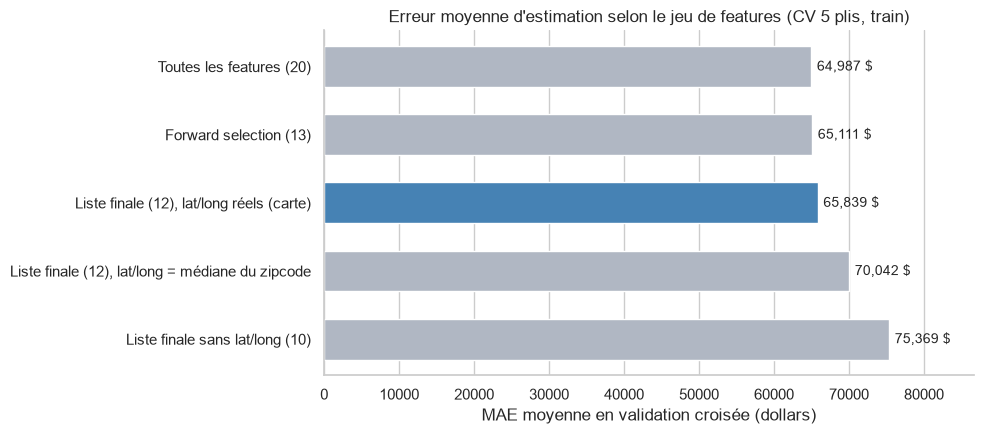

In [20]:
NOM_LISTE_FINALE = "Liste finale (12), lat/long réels (carte)"
mae_par_jeu = validation_jeux["MAE ($)"]
couleurs = ["steelblue" if nom == NOM_LISTE_FINALE else "#b0b7c3" for nom in mae_par_jeu.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
barres = ax.barh(mae_par_jeu.index, mae_par_jeu.to_numpy(), color=couleurs, height=0.6)
ax.invert_yaxis()  # même ordre que le tableau, de haut en bas
ax.bar_label(barres, labels=[f"{v:,.0f} $" for v in mae_par_jeu], padding=4, fontsize=10)
ax.set_xlim(0, mae_par_jeu.max() * 1.15)
ax.set_xlabel("MAE moyenne en validation croisée (dollars)")
ax.set_title("Erreur moyenne d'estimation selon le jeu de features (CV 5 plis, train)", fontsize=12)
ax.grid(axis="y", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture des résultats :**
- **La liste finale coûte très peu :** sa MAE est de 65 839 $, contre 64 987 $ avec les 20 features (+852 $, soit +1,3 %), pour un R² de 0,899 contre 0,903. Retirer 8 features, dont toutes celles qu'on ne peut pas saisir, ne dégrade presque pas le modèle.
- **`lat`/`long` sont décisives :** sans elles, la MAE monte à 75 369 $ (+9 530 $, soit +14 %). Le code postal seul ne suffit pas, car le prix varie fortement à l'intérieur d'une même zone (rue calme ou passante, proximité d'un lac…).
- **La médiane du zipcode est un repli acceptable :** 70 042 $, ce qui récupère environ la moitié de la perte. D'où le choix d'une carte où l'utilisateur clique sur l'emplacement exact, avec la médiane comme valeur par défaut.

> Ces scores sont mesurés avec un `HistGradientBoostingRegressor` par défaut, non optimisé. Ils servent à **comparer des jeux de features** entre eux, pas à annoncer la performance finale, qui sera mesurée une seule fois sur le test (section 6).

### 3.7 Sauvegarde de la table zipcode -> lat/long (pour l'application)

**Quoi :** on calcule, pour chaque code postal, la **médiane de `lat` et `long` sur le train**, et on la sauvegarde dans `models/zipcode_latlong.csv`.

**Pourquoi :**
- Dans l'application, la carte Leaflet sera **centrée sur ce point** quand l'utilisateur choisit un code postal. Si l'utilisateur ne clique pas sur la carte, ce point servira de **valeur de repli** pour `lat`/`long`.
- On utilise la **médiane** plutôt que la moyenne : elle est robuste aux quelques maisons excentrées d'une zone, et elle tombe toujours dans une zone habitée.
- Le calcul se fait sur le **train uniquement**, comme tout ce qui apprend des données. La table fait partie du « modèle » au même titre que l'encodeur, d'où son enregistrement dans `models/`.

In [21]:
CHEMIN_ZIP_LATLONG = "../models/zipcode_latlong.csv"

zipcode_latlong = (
    X_train.groupby("zipcode")[["lat", "long"]]
    .median()
    .reset_index()
)
assert zipcode_latlong["zipcode"].nunique() == X["zipcode"].nunique(), "Un code postal du dataset est absent du train"

zipcode_latlong.to_csv(CHEMIN_ZIP_LATLONG, index=False)
print(f"{len(zipcode_latlong)} codes postaux sauvegardés dans {CHEMIN_ZIP_LATLONG}")
display(zipcode_latlong.head())

70 codes postaux sauvegardés dans ../models/zipcode_latlong.csv


,zipcode,lat,long
0,98001,47.31540,-122.2720
1,98002,47.30560,-122.2140
2,98003,47.32775,-122.3080
3,98004,47.62090,-122.2040
4,98005,47.60280,-122.1685
